In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/experiment_data.csv")

# 1. Basic overview
print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nFirst 5 rows:")
display(df.head())

# 2. Missing values and duplicates
print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())
print("Duplicate user IDs:", df["user_id"].duplicated().sum())

# 3. Experiment assignment
print("\nGroup sizes:")
print(df["variant"].value_counts(dropna=False))

# 4. Validate important fields
print("\nConversion values:")
print(df["converted"].value_counts(dropna=False))

print("\nNegative revenue rows:", (df["revenue"] < 0).sum())
print(
    "Unexpected experiment groups:",
    (~df["variant"].isin(["Control", "Treatment"])).sum()
)

Dataset shape: (50000, 9)

Columns:
['user_id', 'variant', 'device', 'acquisition_channel', 'is_new_user', 'converted', 'revenue', 'contribution_profit', 'experiment_date']

Data types:
user_id                 object
variant                 object
device                  object
acquisition_channel     object
is_new_user              int64
converted                int64
revenue                float64
contribution_profit    float64
experiment_date         object
dtype: object

First 5 rows:


,user_id,variant,device,acquisition_channel,is_new_user,converted,revenue,contribution_profit,experiment_date
0,U000001,Control,Tablet,Direct,1,0,0.00,-0.04,2026-09-14
1,U000002,Control,Tablet,Social,1,0,0.00,-0.04,2026-09-21
2,U000003,Treatment,Mobile,Paid Search,1,0,0.00,-0.10,2026-09-23
3,U000004,Treatment,Mobile,Email,0,0,0.00,-0.10,2026-09-23
4,U000005,Control,Desktop,Organic,0,1,773.48,221.01,2026-09-21



Missing values:
user_id                0
variant                0
device                 0
acquisition_channel    0
is_new_user            0
converted              0
revenue                0
contribution_profit    0
experiment_date        0
dtype: int64

Duplicate rows: 0
Duplicate user IDs: 0

Group sizes:
variant
Control      25000
Treatment    25000
Name: count, dtype: int64

Conversion values:
converted
0    45384
1     4616
Name: count, dtype: int64

Negative revenue rows: 0
Unexpected experiment groups: 0


In [8]:
# Exploratory Data Analysis

# 1. Sample ratio
print(df["variant"].value_counts())
print("\nGroup share (%):")
print((df["variant"].value_counts(normalize=True) * 100).round(2))

# 2. Device distribution by experiment group
device_mix = pd.crosstab(
    df["variant"], df["device"], normalize="index"
) * 100

print("\nDevice mix (%):")
print(device_mix.round(2))

# 3. Acquisition channel distribution
channel_mix = pd.crosstab(
    df["variant"], df["acquisition_channel"], normalize="index"
) * 100

print("\nAcquisition channel mix (%):")
print(channel_mix.round(2))

# 4. New vs returning users
user_mix = pd.crosstab(
    df["variant"], df["is_new_user"], normalize="index"
) * 100

print("\nNew-user mix (%):")
print(user_mix.rename(columns={0: "Returning", 1: "New"}).round(2))

variant
Control      25000
Treatment    25000
Name: count, dtype: int64

Group share (%):
variant
Control      50.0
Treatment    50.0
Name: proportion, dtype: float64

Device mix (%):
device     Desktop  Mobile  Tablet
variant                           
Control      30.84   62.12    7.05
Treatment    30.95   62.04    7.01

Acquisition channel mix (%):
acquisition_channel  Direct  Email  Organic  Paid Search  Social
variant                                                         
Control               14.92  11.74    30.38        24.75   18.20
Treatment             15.04  11.96    29.89        25.24   17.87

New-user mix (%):
is_new_user  Returning    New
variant                      
Control          42.08  57.92
Treatment        42.41  57.59


           Users  Conversions  Conversion_Rate  Total_Revenue  \
variant                                                         
Control    25000         2199             8.80     2038078.32   
Treatment  25000         2417             9.67     2168065.83   

           Revenue_Per_User  Total_Profit  Profit_Per_User  
variant                                                     
Control               81.52     581833.11            23.27  
Treatment             86.72     619625.62            24.79  


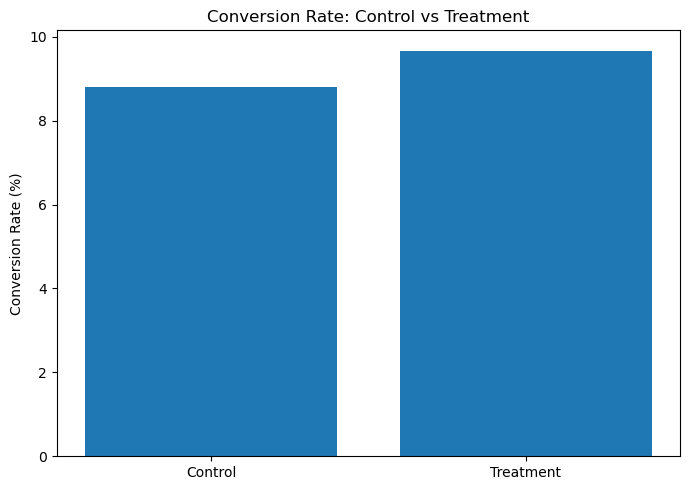

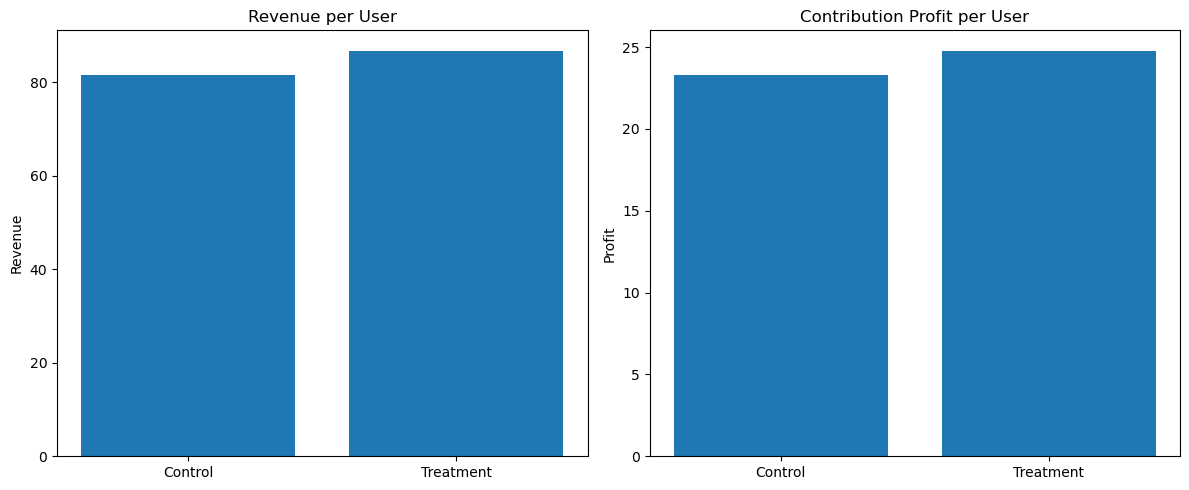

In [9]:
# Group-level metrics
summary = df.groupby("variant").agg(
    Users=("user_id", "nunique"),
    Conversions=("converted", "sum"),
    Conversion_Rate=("converted", "mean"),
    Total_Revenue=("revenue", "sum"),
    Revenue_Per_User=("revenue", "mean"),
    Total_Profit=("contribution_profit", "sum"),
    Profit_Per_User=("contribution_profit", "mean")
)

summary["Conversion_Rate"] *= 100

print(summary.round(2))

# Conversion rate
plt.figure(figsize=(7, 5))
plt.bar(summary.index, summary["Conversion_Rate"])
plt.ylabel("Conversion Rate (%)")
plt.title("Conversion Rate: Control vs Treatment")
plt.tight_layout()
plt.show()

# Revenue and profit per user
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].bar(summary.index, summary["Revenue_Per_User"])
axes[0].set_title("Revenue per User")
axes[0].set_ylabel("Revenue")

axes[1].bar(summary.index, summary["Profit_Per_User"])
axes[1].set_title("Contribution Profit per User")
axes[1].set_ylabel("Profit")

plt.tight_layout()
plt.show()


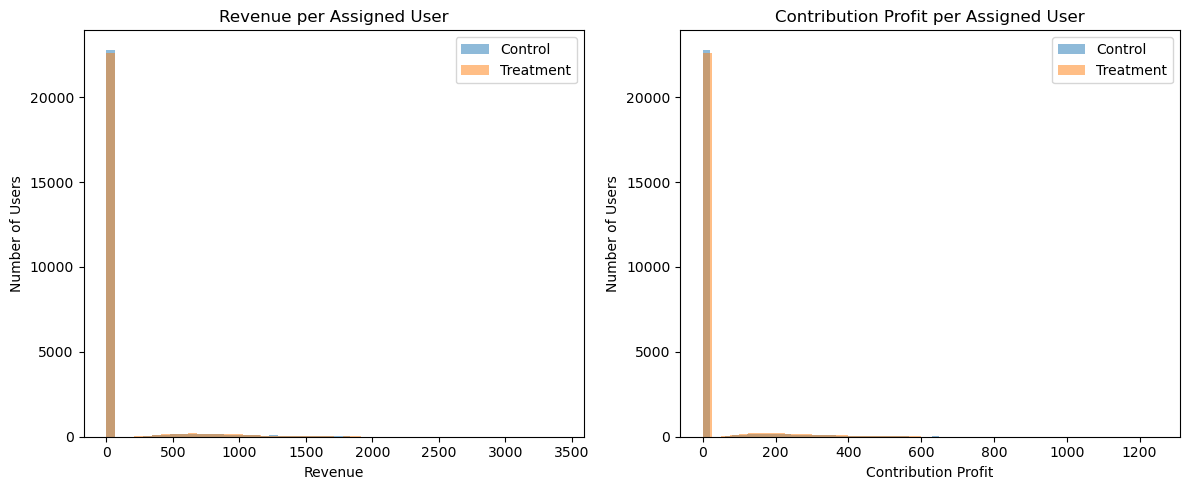

           Revenue_Median  Revenue_Std  Revenue_P95  Profit_Median  \
variant                                                              
Control               0.0       295.63       765.44          -0.04   
Treatment             0.0       299.72       792.98          -0.10   

           Profit_Std  Profit_P95  
variant                            
Control         86.17      212.22  
Treatment       87.94      221.09  


In [10]:
# distribution and outliers

# Compare distributions
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for group in ["Control", "Treatment"]:
    subset = df.loc[df["variant"] == group, "revenue"]
    axes[0].hist(subset, bins=50, alpha=0.5, label=group)

axes[0].set_title("Revenue per Assigned User")
axes[0].set_xlabel("Revenue")
axes[0].set_ylabel("Number of Users")
axes[0].legend()

for group in ["Control", "Treatment"]:
    subset = df.loc[df["variant"] == group, "contribution_profit"]
    axes[1].hist(subset, bins=50, alpha=0.5, label=group)

axes[1].set_title("Contribution Profit per Assigned User")
axes[1].set_xlabel("Contribution Profit")
axes[1].set_ylabel("Number of Users")
axes[1].legend()

plt.tight_layout()
plt.show()

distribution_summary = df.groupby("variant").agg(
    Revenue_Median=("revenue", "median"),
    Revenue_Std=("revenue", "std"),
    Revenue_P95=("revenue", lambda x: x.quantile(0.95)),
    Profit_Median=("contribution_profit", "median"),
    Profit_Std=("contribution_profit", "std"),
    Profit_P95=("contribution_profit", lambda x: x.quantile(0.95))
)

print(distribution_summary.round(2))



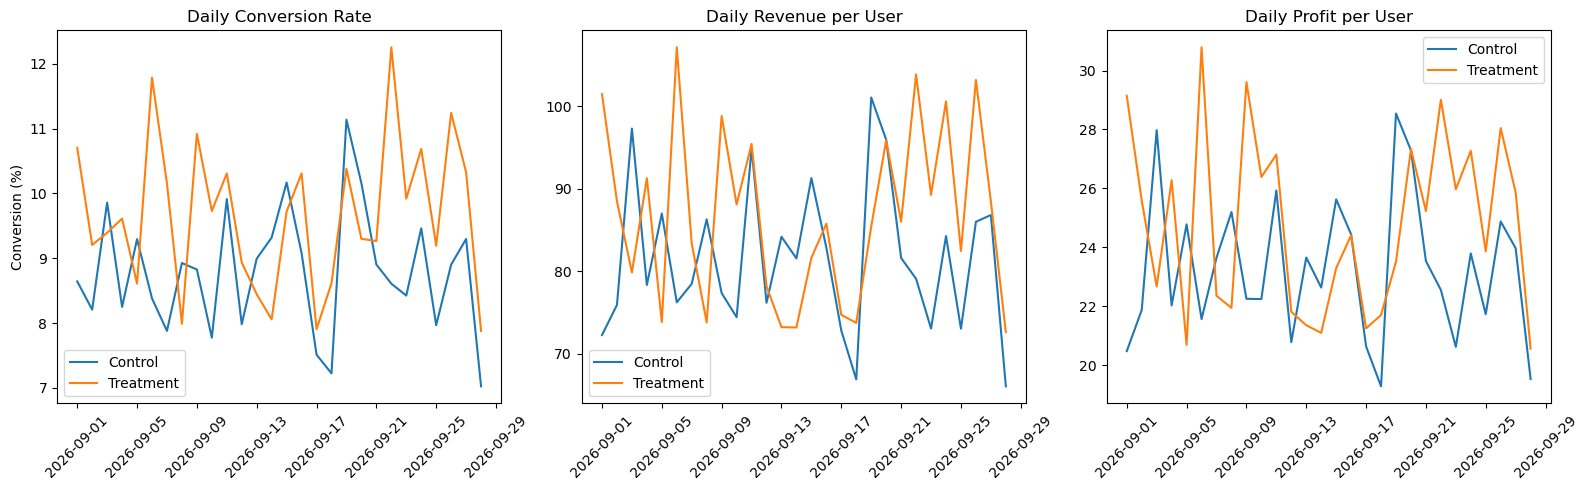

In [11]:
# Check experiment dates

df["experiment_date"] = pd.to_datetime(df["experiment_date"])

daily = df.groupby(
    ["experiment_date", "variant"]
).agg(
    Users=("user_id", "nunique"),
    Conversion_Rate=("converted", "mean"),
    Revenue_Per_User=("revenue", "mean"),
    Profit_Per_User=("contribution_profit", "mean")
).reset_index()

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for group in ["Control", "Treatment"]:
    data = daily[daily["variant"] == group]

    axes[0].plot(
        data["experiment_date"], data["Conversion_Rate"] * 100,
        label=group
    )
    axes[1].plot(
        data["experiment_date"], data["Revenue_Per_User"],
        label=group
    )
    axes[2].plot(
        data["experiment_date"], data["Profit_Per_User"],
        label=group
    )

axes[0].set_title("Daily Conversion Rate")
axes[0].set_ylabel("Conversion (%)")
axes[1].set_title("Daily Revenue per User")
axes[2].set_title("Daily Profit per User")

for ax in axes:
    ax.tick_params(axis="x", rotation=45)
    ax.legend()

plt.tight_layout()
plt.show()